# Altitude du sommet des nuages : variables spectrales et textures

**Objectif :** mesurer l'apport des filtres de Gabor et des ondelettes à la prédiction
de `Cloud_Top_Altitude_EarthCARE`, en comparaison avec un MLP inspiré de `ctth_IA.py`.
Ce notebook réalise l'audit, l'extraction, la validation par dates, la sélection
d'une configuration, l'évaluation finale et les cas d'étude.

Les sorties sont créées à l'exécution dans `resultats_notebook/`. Aucun résultat
scientifique n'est prérempli. La référence conserve les familles de variables et
les couches (64, 32) du script, mais utilise **scikit-learn** : elle ne reproduit
pas exactement son réseau Keras (normalisation de couches et régularisation différentes).

**Installation :** depuis ce dossier, exécuter `python -m pip install -r requirements-notebook.txt`,
puis `jupyter lab`. Sélectionner le noyau de cet environnement et exécuter les cellules dans l'ordre.


In [18]:
from pathlib import Path
import json, platform, warnings, importlib.metadata, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
from skimage.filters import gabor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning
import joblib
from IPython.display import display

ROOT = Path.cwd()
# Facultatif : chemin du dossier contenant les données (local ou Kaggle).
# Exemple : DATA_DIR = Path('/kaggle/input/mon-dataset')
DATA_DIR = None
OUT = ROOT / 'resultats_notebook'
OUT.mkdir(exist_ok=True)
SEED = 42
TARGET = 'Cloud_Top_Altitude_EarthCARE'
DAY = 'Day_UTC'
TYPE = 'Cloud_Type_SAFNWC'
SAF = 'Cloud_Top_Altitude_SAFNWC'
CHANNELS = ['WV_063', 'WV_073', 'IR_087', 'IR_105', 'IR_123', 'IR_133']

# Mode exploratoire : échantillon reproductible avant toute expérience.
# Mettre None pour utiliser tous les points (calcul de textures potentiellement long).
MAX_ROWS = 3000
REQUESTED_FOLDS = 50  
TEST_DATE_FRACTION = 0.20
MAX_ITER = 500
PERMUTATION_REPEATS = 3

# Vecteurs aplatis : confirmer l'ordre spatial auprès du producteur des données.
PATCH_LAYOUT_CONFIRMED = False
PATCH_ORDER = 'C'
GABOR_FREQUENCIES = (0.15, 0.30)
GABOR_ANGLES = (0, np.pi/4, np.pi/2, 3*np.pi/4)
WAVELET = 'haar'

# Jointure du parquet : renseigner des identifiants d'observations fiables.
# Exemple uniquement : JOIN_KEYS = ['Day_UTC', 'HH_UTC', 'MN_UTC', 'pixel_id']
JOIN_KEYS = []
# Activer seulement après confirmation externe que les lignes correspondent exactement.
ALLOW_POSITIONAL_ALIGNMENT = False
USE_EXTERNAL_FEATURES = False  # Activer après audit de leur provenance et absence de fuite.
EXTERNAL_FEATURE_COLUMNS = []  # Liste explicite, excluant cibles et produits dérivés de celles-ci.

print('Dossier :', ROOT)


Dossier : /kaggle/working


## 1. Charger et documenter les données

Le pickle local est supposé provenir d'une source de confiance. Le parquet est audité
séparément : une même longueur ou un index numérique ordinaire ne prouvent pas
l'alignement des observations. Les unités doivent être confirmées dans la documentation
du producteur ; les évaluations supposent que les altitudes EarthCARE et SAFNWC sont en mètres.


In [19]:
def find_data_file(filename, data_dir=None):
    if data_dir is not None:
        candidate = Path(data_dir).expanduser() / filename
        if candidate.is_file():
            return candidate
        raise FileNotFoundError(f'Fichier absent du DATA_DIR configuré : {candidate}')
    local = Path.cwd() / filename
    if local.is_file():
        return local
    kaggle_input = Path('/kaggle/input')
    matches = sorted(p for p in kaggle_input.rglob(filename) if p.is_file()) if kaggle_input.is_dir() else []
    if len(matches) == 1:
        return matches[0]
    if len(matches) > 1:
        raise ValueError(f'Plusieurs fichiers {filename} trouvés : {matches}. Renseigner DATA_DIR dans la première cellule.')
    raise FileNotFoundError(
        f'{filename} introuvable dans {Path.cwd()} et /kaggle/input. '
        'Sur Kaggle, ajouter le dataset via Add Input ; sinon renseigner DATA_DIR '
        'dans la première cellule, puis relancer les cellules dans l’ordre.'
    )

PICKLE_PATH = find_data_file('data_cloud_top_V2.pkl', DATA_DIR)
SPATIAL_PATH = find_data_file('spatial_features_v2.parquet', DATA_DIR)
print('Pickle :', PICKLE_PATH, '\nParquet :', SPATIAL_PATH)
raw = pd.read_pickle(PICKLE_PATH)
spatial = pd.read_parquet(SPATIAL_PATH)
if not isinstance(raw, pd.DataFrame):
    raise TypeError('Le pickle doit contenir un DataFrame ; adapter le chargeur au format constaté.')
if not raw.columns.is_unique or not spatial.columns.is_unique:
    raise ValueError('Noms de colonnes dupliqués : résoudre avant de poursuivre.')
missing = {TARGET, DAY} - set(raw.columns)
if missing:
    raise ValueError(f'Colonnes obligatoires absentes : {missing}')

def audit_frame(frame):
    records = []
    for col in frame:
        s = frame[col]
        example = next((v for v in s if v is not None and np.asarray(v).size), None)
        shape = np.asarray(example).shape if example is not None else ()
        record = {'variable': str(col), 'dtype': str(s.dtype),
                  'dimension_exemple': str(shape), 'manquants_cellules': int(s.isna().sum()),
                  'unite': 'à confirmer'}
        if pd.api.types.is_numeric_dtype(s):
            values = pd.to_numeric(s, errors='coerce').replace([np.inf, -np.inf], np.nan)
            record.update(min=values.min(), mediane=values.median(), max=values.max())
        records.append(record)
    return pd.DataFrame(records)

audit = audit_frame(raw)
audit.to_csv(OUT / 'dictionnaire_variables.csv', index=False)
audit_frame(spatial).to_csv(OUT / 'dictionnaire_spatial.csv', index=False)
print('Données principales :', raw.shape, '| parquet :', spatial.shape)
display(audit)
display(spatial.head(3))
display(raw.groupby(DAY, dropna=False).size().rename('observations').to_frame())
print('Index principaux uniques :', raw.index.is_unique,
      '| index spatiaux uniques :', spatial.index.is_unique)
if TYPE in raw:
    display(raw[TYPE].value_counts(dropna=False).rename('observations').to_frame())

# Aucune suppression de doublons fondée uniquement sur les valeurs radiométriques.
if JOIN_KEYS:
    print('Identifiants dupliqués :', raw.duplicated(JOIN_KEYS).sum(),
          spatial.duplicated(JOIN_KEYS).sum())

eligible = raw.loc[raw[DAY].notna() & np.isfinite(pd.to_numeric(raw[TARGET], errors='coerce'))].copy()
print('Lignes exclues (date/cible absente ou cible non finie) :', len(raw) - len(eligible))
# Trier les dates : vérifier leur représentation avant d'interpréter la chronologie.
dates = sorted(eligible[DAY].unique())
if len(dates) < 4:
    raise ValueError('Au moins quatre dates distinctes sont nécessaires à ce protocole.')
if MAX_ROWS is not None and len(eligible) > MAX_ROWS:
    # Un échantillonnage par date préserve tous les groupes disponibles.
    if MAX_ROWS < len(dates):
        raise ValueError('MAX_ROWS doit être au moins égal au nombre de dates.')
    quota = MAX_ROWS // len(dates)
    parts = [part.sample(n=min(len(part), quota), random_state=SEED)
             for _, part in eligible.groupby(DAY, sort=True)]
    data = pd.concat(parts).copy()
else:
    data = eligible.copy()
# Identifiant de ligne indépendant des éventuels doublons d'index du pickle.
data['_source_position'] = raw.index.get_indexer(data.index) if raw.index.is_unique else -1
data = data.reset_index(drop=True)
print('Observations retenues :', len(data), '| dates :', data[DAY].nunique())


Pickle : /kaggle/input/datasets/rayhansaouir/spatial/data_cloud_top_V2.pkl 
Parquet : /kaggle/input/datasets/rayhansaouir/spatial/spatial_features_v2.parquet
Données principales : (87746, 45) | parquet : (87746, 72)


,variable,dtype,dimension_exemple,manquants_cellules,unite,min,mediane,max
0,Cloud_Type_SAFNWC,int32,(),0,à confirmer,5.000000,6.000000,14.000000
1,WV_073_ClearSky,object,(),0,à confirmer,NaN,NaN,NaN
2,WV_073_W5,float64,(),0,à confirmer,192.779999,257.290009,274.679993
3,IR_123_W5,float64,(),0,à confirmer,190.239990,280.109985,323.070007
4,WV_063_W5,float64,(),0,à confirmer,192.619995,239.649994,262.600006
5,IR_087_C5,float64,(),0,à confirmer,190.130005,272.369995,308.389984
6,WV_073_std5,float64,(),0,à confirmer,0.012796,0.328657,20.962282
7,nb_pix_LON_cor_parallax,int64,(),0,à confirmer,-3.000000,0.000000,3.000000
8,nb_pix_LAT_cor_parallax,int64,(),0,à confirmer,-3.000000,0.000000,3.000000
9,IR_133_C5,float64,(),0,à confirmer,190.910004,260.429993,284.660004


,gabor_wv063_l3_e,gabor_wv063_l3_aniso,gabor_wv063_l4_e,gabor_wv063_l4_aniso,gabor_wv063_l6_e,gabor_wv063_l6_aniso,scat_wv063_l3x4_par,scat_wv063_l3x4_all,scat_wv063_l3x6_par,scat_wv063_l3x6_all,...,gabor_ir133_l4_e,gabor_ir133_l4_aniso,gabor_ir133_l6_e,gabor_ir133_l6_aniso,scat_ir133_l3x4_par,scat_ir133_l3x4_all,scat_ir133_l3x6_par,scat_ir133_l3x6_all,scat_ir133_l4x6_par,scat_ir133_l4x6_all
0,0.004918,0.163756,0.019570,0.287694,0.092818,0.386435,0.048354,0.034345,0.099595,0.077285,...,5.828618,0.147519,16.811029,0.127509,0.614382,0.557720,1.270673,1.287359,1.875582,2.025955
1,0.005186,0.161769,0.018250,0.224140,0.080520,0.348963,0.048464,0.035968,0.103053,0.076546,...,5.664583,0.128431,13.805993,0.158040,0.605289,0.579147,1.184882,1.245754,1.613500,1.882717
2,0.005542,0.182415,0.020512,0.197109,0.072503,0.307487,0.055997,0.040697,0.106961,0.080350,...,5.171160,0.126854,11.655782,0.161240,0.507634,0.539654,0.984159,1.124850,1.474701,1.635117


,observations
Day_UTC,
20250613,3816
20250614,8525
20250615,7307
20250616,4962
20250618,7779
20250619,7943
20250620,6323
20250621,5969
20250622,3295


Index principaux uniques : True | index spatiaux uniques : True


,observations
Cloud_Type_SAFNWC,
5,30694
6,16278
10,8313
12,8249
7,8113
8,6072
11,4197
14,3258
13,1755


Lignes exclues (date/cible absente ou cible non finie) : 0
Observations retenues : 2990 | dates : 13


## 2. Construire les variables de référence et visualiser les voisinages

Les six canaux centraux, les six simulations ciel clair, les statistiques de voisinage
et les sept températures ERA5 sont recherchés explicitement. Les familles absentes sont
signalées. Aucune colonne numérique arbitraire n'entre dans le modèle.

Pour un vecteur de 25 valeurs, le script original prend l'indice 12 comme centre.
La reconstruction 5 × 5 reste désactivée tant que `PATCH_LAYOUT_CONFIRMED` vaut `False`.
Les tableaux déjà bidimensionnels sont utilisables directement. Un contexte 5 × 5
limite fortement l'interprétation des textures ; des images plus grandes seraient une extension.


Variables présentes : 37 | absentes : []


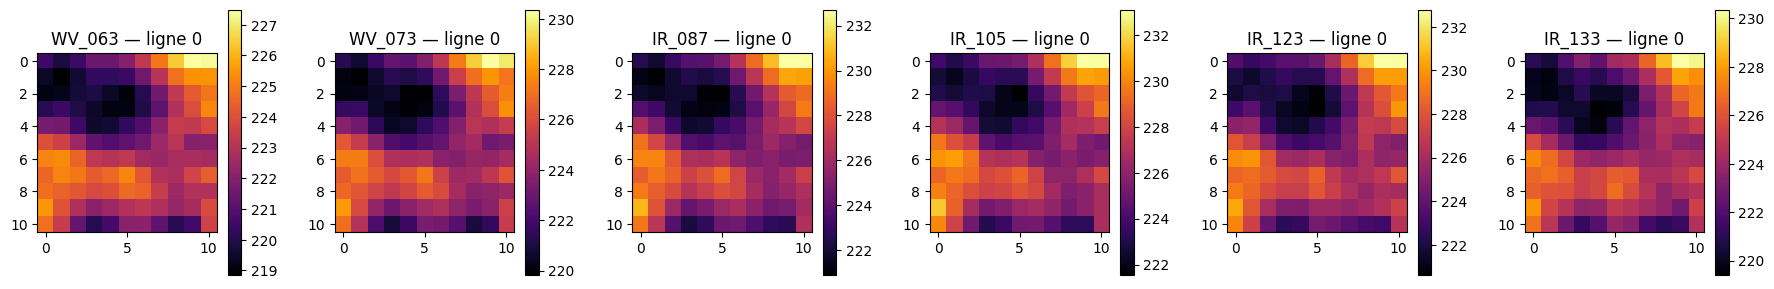

In [20]:
def center_value(value):
    try:
        a = np.asarray(value, dtype=float)
        if a.ndim == 0:
            return float(a)
        if a.ndim == 2 and all(s % 2 for s in a.shape):
            return float(a[a.shape[0]//2, a.shape[1]//2])
        if a.ndim == 1 and a.size % 2:
            return float(a[a.size//2])
    except (TypeError, ValueError):
        pass
    return np.nan

expected = (CHANNELS + [c + '_ClearSky' for c in CHANNELS]
            + [f'{c}_{stat}5' for c in CHANNELS for stat in ['C', 'W', 'std']]
            + [f'T_{p}' for p in [1000, 850, 700, 500, 300, 200, 100]])
baseline_cols = [c for c in expected if c in data]
print('Variables présentes :', len(baseline_cols), '| absentes :', sorted(set(expected)-set(data.columns)))
if not baseline_cols:
    raise ValueError('Aucune variable de référence reconnue ; consulter le dictionnaire.')
X_base = pd.DataFrame({c: data[c].map(center_value) for c in baseline_cols}).replace([np.inf, -np.inf], np.nan)
if X_base.notna().sum().sum() == 0:
    raise ValueError('Toutes les variables de référence sont invalides.')
y = pd.to_numeric(data[TARGET]).astype(float)

def as_patch(value):
    try:
        a = np.asarray(value, dtype=float)
    except (TypeError, ValueError):
        return None
    if a.ndim == 1 and PATCH_LAYOUT_CONFIRMED:
        side = int(np.sqrt(a.size))
        if side * side == a.size:
            a = a.reshape(side, side, order=PATCH_ORDER)
    if a.ndim != 2 or min(a.shape) < 2:
        return None
    # Aucune imputation spatiale silencieuse : une texture manquante sera imputée sur train.
    return a if np.isfinite(a).all() else None

patch_channels = [c for c in CHANNELS if c in data]
examples = []
for c in patch_channels:
    for i, v in data[c].items():
        patch = as_patch(v)
        if patch is not None:
            examples.append((i, c, patch))
            break
if examples:
    fig, axes = plt.subplots(1, len(examples), figsize=(3*len(examples), 3), squeeze=False)
    for ax, (i, c, p) in zip(axes[0], examples):
        im = ax.imshow(p, cmap='inferno'); ax.set_title(f'{c} — ligne {i}')
        fig.colorbar(im, ax=ax)
    plt.tight_layout(); plt.show()
else:
    print('Pas de patch 2D confirmé : expériences Gabor/ondelettes indisponibles pour cette exécution.')


## 3. Extraire Gabor et les ondelettes

Gabor est appliqué aux anomalies locales (moyenne du patch retirée) pour caractériser
les variations spatiales. Chaque réponse fournit énergie et écart-type du module.
Les ondelettes Haar fournissent l'énergie moyenne des quatre sous-bandes à un niveau,
sans dépasser le niveau admissible pour la taille du patch. Les bords utilisent une
extension symétrique ; leur influence peut être forte sur les petits voisinages.


Textures : 1000/2990
Textures : 2000/2990
Dimensions : {'reference': (2990, 37), 'Gabor': 96, 'ondelettes': 24}


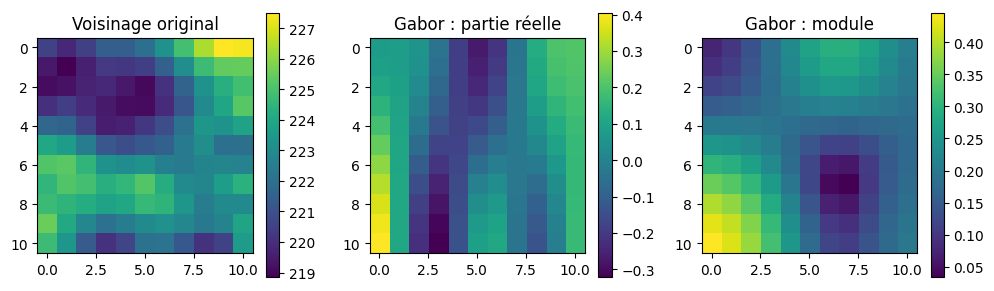

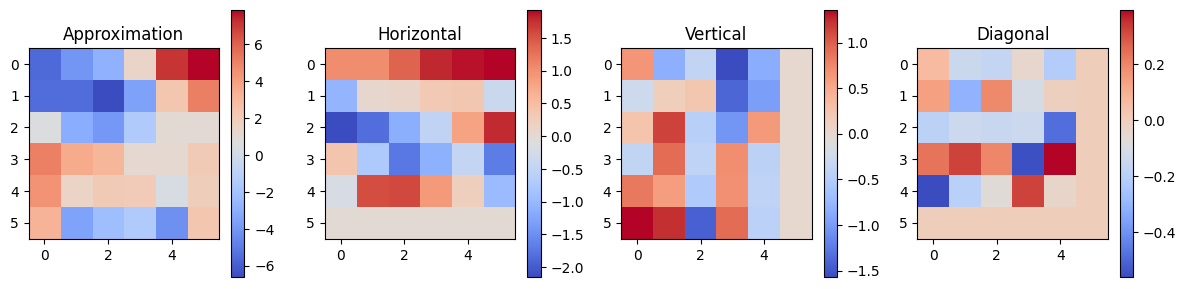

In [21]:
def texture_features(patch, channel):
    features = {}
    centered = patch - patch.mean()
    for fi, frequency in enumerate(GABOR_FREQUENCIES):
        for ti, theta in enumerate(GABOR_ANGLES):
            real, imag = gabor(centered, frequency=frequency, theta=theta, mode='reflect')
            amplitude = np.hypot(real, imag)
            prefix = f'{channel}__gabor_f{fi}_o{ti}'
            features[prefix + '_energy'] = float(np.mean(amplitude**2))
            features[prefix + '_std'] = float(amplitude.std())
    level = pywt.dwtn_max_level(patch.shape, WAVELET)
    if level >= 1:
        approx, details = pywt.dwt2(centered, WAVELET, mode='symmetric')
        for name, arr in zip(['A', 'H', 'V', 'D'], [approx, *details]):
            features[f'{channel}__wavelet_{name}_energy'] = float(np.mean(arr**2))
    return features

rows = []
for i, row in data[patch_channels].iterrows():
    features = {}
    for channel in patch_channels:
        patch = as_patch(row[channel])
        if patch is not None:
            features.update(texture_features(patch, channel))
    rows.append(features)
    if (i + 1) % 1000 == 0:
        print(f'Textures : {i+1}/{len(data)}')
textures = pd.DataFrame(rows, index=data.index).replace([np.inf, -np.inf], np.nan)
gabor_cols = [c for c in textures if '__gabor_' in c]
wavelet_cols = [c for c in textures if '__wavelet_' in c]
print('Dimensions :', {'reference': X_base.shape, 'Gabor': len(gabor_cols), 'ondelettes': len(wavelet_cols)})
textures.to_parquet(OUT / 'textures_calculees.parquet', index=True)

if examples:
    _, channel, patch = examples[0]
    real, imag = gabor(patch-patch.mean(), frequency=GABOR_FREQUENCIES[0], theta=GABOR_ANGLES[0], mode='reflect')
    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    for ax, arr, title in zip(axes, [patch, real, np.hypot(real, imag)],
                              ['Voisinage original', 'Gabor : partie réelle', 'Gabor : module']):
        im = ax.imshow(arr, cmap='viridis'); ax.set_title(title); fig.colorbar(im, ax=ax)
    plt.tight_layout(); plt.savefig(OUT / 'exemple_gabor.png', dpi=150); plt.show()
    if pywt.dwtn_max_level(patch.shape, WAVELET) >= 1:
        a, (h, v, d) = pywt.dwt2(patch-patch.mean(), WAVELET, mode='symmetric')
        fig, axes = plt.subplots(1, 4, figsize=(12, 3))
        for ax, arr, title in zip(axes, [a,h,v,d], ['Approximation','Horizontal','Vertical','Diagonal']):
            im = ax.imshow(arr, cmap='coolwarm'); ax.set_title(title); fig.colorbar(im, ax=ax)
        plt.tight_layout(); plt.savefig(OUT / 'exemple_ondelettes.png', dpi=150); plt.show()


## 4. Intégrer éventuellement le parquet existant

La jointure exige des clés uniques, un index explicite fiable ou une confirmation
de l'ordre des lignes. Choisir les colonnes après audit de leur provenance : exclure
EarthCARE, SAFNWC, leurs dérivés et toute information indisponible au moment de la prédiction.
Le parquet est une expérience supplémentaire ; il ne remplace pas les textures calculées ci-dessus.


In [22]:
external = pd.DataFrame(index=data.index)
if USE_EXTERNAL_FEATURES:
    if not EXTERNAL_FEATURE_COLUMNS:
        raise ValueError('Renseigner EXTERNAL_FEATURE_COLUMNS après audit de provenance.')
    forbidden = {TARGET, SAF, TYPE, DAY, 'CloudTops_Layers_0', '_source_position'}
    if forbidden.intersection(EXTERNAL_FEATURE_COLUMNS):
        raise ValueError('Une colonne exclue a été sélectionnée comme prédicteur externe.')
    if JOIN_KEYS:
        for frame in (raw, spatial):
            if frame[JOIN_KEYS].isna().any().any() or frame.duplicated(JOIN_KEYS).any():
                raise ValueError('Clés de jointure nulles ou non uniques.')
        merged = data[JOIN_KEYS].merge(spatial[JOIN_KEYS + EXTERNAL_FEATURE_COLUMNS],
                                       on=JOIN_KEYS, how='left', validate='one_to_one', indicator=True)
        if not merged['_merge'].eq('both').all():
            raise ValueError('Certaines observations ne correspondent à aucune ligne du parquet.')
        external = merged[EXTERNAL_FEATURE_COLUMNS].set_axis(data.index)
    elif ALLOW_POSITIONAL_ALIGNMENT and len(raw) == len(spatial) and raw.index.is_unique:
        external = spatial.iloc[data['_source_position'].to_numpy()][EXTERNAL_FEATURE_COLUMNS].reset_index(drop=True)
    else:
        raise ValueError('Alignement non prouvé : renseigner JOIN_KEYS ou confirmer explicitement l’ordre.')
    external = external.apply(pd.to_numeric, errors='raise').replace([np.inf, -np.inf], np.nan)
    external = external.add_prefix('external__')
print('Dimensions externes :', external.shape)


Dimensions externes : (2990, 0)


## 5. Réserver le test et explorer uniquement le développement

Les dernières dates triées sont réservées au test final. Vérifier que `Day_UTC` est
une date chronologique (et non un simple numéro de jour cyclique). La validation croisée
groupe les observations par date ; elle mesure le transfert entre journées observées,
pas nécessairement la prévision de journées futures. Des orbites ou scènes communes
à plusieurs dates pourraient nécessiter un regroupement plus strict.


50 folds demandés, 10 dates de développement : 10 folds utilisés.
Développement : 2300 | test réservé : 690 | folds : 10
Dates de test : ['20250628', '20250629', '20250630']


,count,mean,std,min,25%,50%,75%,max
WV_063,2300.0,239.660769,7.880779,206.419998,234.584995,238.749992,245.319992,259.809998
WV_073,2300.0,254.470360,10.127459,207.000000,249.044991,256.010010,261.742493,272.820007
IR_087,2300.0,272.640680,15.099066,207.130005,264.539993,276.940002,283.557487,318.260010
IR_105,2300.0,274.065907,15.569714,207.350006,265.987480,278.449982,285.239990,322.609985
IR_123,2300.0,271.495441,15.322974,206.199997,263.277504,276.099991,282.809998,316.779999
IR_133,2300.0,260.072782,12.130755,206.339996,253.669998,263.649994,269.359985,288.449982
WV_063_ClearSky,2300.0,240.506351,6.375728,227.563126,235.924339,239.075340,245.114750,258.643921
WV_073_ClearSky,2300.0,259.002428,5.964968,243.292618,255.542274,258.825378,263.157845,273.684998
IR_087_ClearSky,2300.0,288.737151,7.237970,267.644104,286.207031,290.233185,292.486542,316.796600
IR_105_ClearSky,2300.0,290.483588,7.357351,270.189392,287.924896,291.613052,293.867111,321.394043


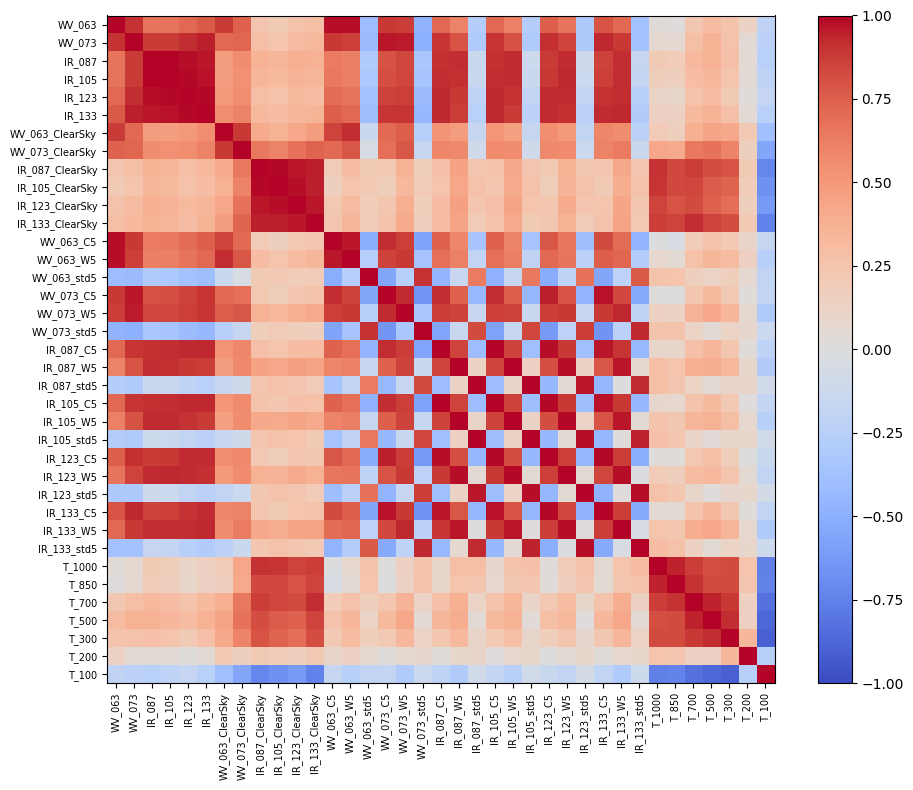

In [23]:
dates = sorted(data[DAY].unique())
n_test = max(1, int(np.ceil(len(dates) * TEST_DATE_FRACTION)))
test_dates = dates[-n_test:]
test_idx = np.flatnonzero(data[DAY].isin(test_dates))
dev_idx = np.flatnonzero(~data[DAY].isin(test_dates))
groups = data.iloc[dev_idx][DAY].to_numpy()
n_groups = len(np.unique(groups))
if n_groups < 2 or len(dev_idx) < 10:
    raise ValueError('Trop peu de données de développement.')
n_folds = min(REQUESTED_FOLDS, n_groups)
if n_folds < 2:
    raise ValueError('Demander au moins deux folds.')
if n_folds != REQUESTED_FOLDS:
    print(f'{REQUESTED_FOLDS} folds demandés, {n_groups} dates de développement : {n_folds} folds utilisés.')
splits = [(dev_idx[tr], dev_idx[va]) for tr, va in GroupKFold(n_splits=n_folds).split(dev_idx, groups=groups)]
for tr, va in splits:
    assert set(data.iloc[tr][DAY]).isdisjoint(data.iloc[va][DAY])
    assert set(data.iloc[tr][DAY]).isdisjoint(test_dates)
pd.DataFrame({'ligne': data.index, 'date': data[DAY],
              'partition': np.where(data[DAY].isin(test_dates), 'test', 'developpement')}).to_csv(OUT / 'partitions.csv', index=False)
print('Développement :', len(dev_idx), '| test réservé :', len(test_idx), '| folds :', n_folds)
print('Dates de test :', test_dates)

explore = X_base.iloc[dev_idx]
display(explore.describe().T)
corr = explore.corr()
corr.to_csv(OUT / 'correlations_reference.csv')
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)), corr.index, fontsize=7)
fig.colorbar(im, ax=ax); plt.tight_layout()
plt.savefig(OUT / 'correlations_reference.png', dpi=150); plt.show()


## 6. Comparer les configurations sur les mêmes folds

Imputation, normalisation et sélection de variables sont réajustées dans chaque
entraînement. Le réseau utilise une graine fixe et désactive sa validation aléatoire
interne pour conserver le découpage par dates. La cible est exprimée en kilomètres
pendant l'ajustement et reconvertie en mètres à la prédiction pour faciliter l'optimisation.
Un avertissement de convergence appelle une inspection et éventuellement une augmentation
de `MAX_ITER` avant de figer le protocole. Les écarts-types entre folds ne sont pas
des intervalles de confiance indépendants.


reference fold 1 MAE = 871.32 m | convergence : True
reference fold 2 MAE = 815.86 m | convergence : True
reference fold 3 MAE = 1057.84 m | convergence : True
reference fold 4 MAE = 725.27 m | convergence : True
reference fold 5 MAE = 909.99 m | convergence : True
reference fold 6 MAE = 733.15 m | convergence : True
reference fold 7 MAE = 931.87 m | convergence : True
reference fold 8 MAE = 861.34 m | convergence : True
reference fold 9 MAE = 823.05 m | convergence : True
reference fold 10 MAE = 1020.7 m | convergence : True
gabor fold 1 MAE = 940.44 m | convergence : True
gabor fold 2 MAE = 1248.92 m | convergence : True
gabor fold 3 MAE = 1327.51 m | convergence : True
gabor fold 4 MAE = 903.37 m | convergence : True
gabor fold 5 MAE = 1002.55 m | convergence : True
gabor fold 6 MAE = 937.05 m | convergence : True
gabor fold 7 MAE = 1093.11 m | convergence : True
gabor fold 8 MAE = 1038.17 m | convergence : True
gabor fold 9 MAE = 1008.21 m | convergence : True
gabor fold 10 MAE = 1

MAE                     RMSE                  biais  \
                    mean         std         mean         std       mean   
experience                                                                 
reference     875.037935  109.572661  1381.843708  309.900970 -27.568544   
ondelettes    975.309001  180.650881  1734.671408  553.644002   5.828074   
gabor        1081.068301  158.989571  1743.416065  265.559047 -43.581400   
combinaison  1124.825186  189.907365  1822.410458  339.173953  13.696880   
selection    1370.650903  187.432247  2088.683825  330.771306 -11.317344   

                               R2            
                    std      mean       std  
experience                                   
reference    238.976570  0.880480  0.075859  
ondelettes   191.928785  0.806262  0.153359  
gabor        174.920131  0.818561  0.082115  
combinaison  208.218691  0.797852  0.106128  
selection    196.624274  0.742261  0.102882

Gains de MAE par rapport à la référence (positif = amélioration) :


,mean,std,min,max
experience,,,,
combinaison,-249.787251,132.525116,-535.173631,-85.550536
gabor,-206.030366,104.593902,-433.067319,-69.116411
ondelettes,-100.271066,116.475641,-346.928043,40.329874
reference,0.000000,0.000000,0.000000,0.000000
selection,-495.612967,157.282296,-723.112770,-295.067650


,sum,mean
experience,,
combinaison,50.268489,5.026849
gabor,50.802430,5.080243
ondelettes,33.267556,3.326756
reference,30.300956,3.030096
selection,33.239709,3.323971


Attention : au moins un ajustement a atteint la limite d’itérations ; résultats exploratoires.


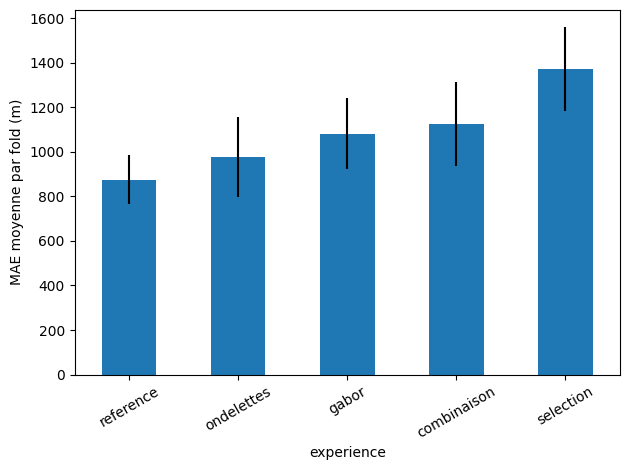

,mean,std
variable,,
IR_133_ClearSky,2380.898579,488.382290
IR_123_ClearSky,1418.020603,457.774056
IR_105,1067.977904,203.802643
IR_087_C5,1059.651192,219.618457
IR_087,1004.616239,121.490130
WV_073_C5,946.932598,315.775092
IR_105_std5,831.945670,248.722862
WV_063_C5,786.034538,311.067009
WV_073_ClearSky,760.570583,228.811705


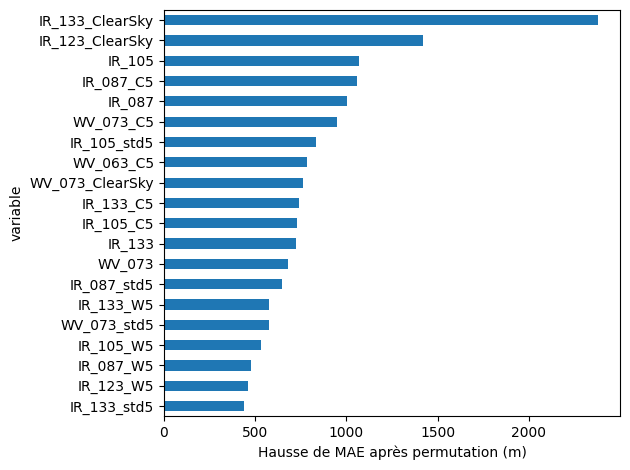

In [24]:
def make_model(n_features, selection=False):
    steps = [('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
             ('scaler', StandardScaler())]
    if selection:
        steps.append(('selection', SelectKBest(f_regression, k=min(20, n_features))))
    steps.append(('mlp', MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu',
                                    alpha=0.01, learning_rate_init=0.001,
                                    max_iter=MAX_ITER, batch_size='auto',
                                    early_stopping=False, random_state=SEED)))
    return Pipeline(steps)

def metrics(actual, predicted):
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual, predicted = actual[valid], predicted[valid]
    if not len(actual):
        return dict(n=0, MAE=np.nan, RMSE=np.nan, biais=np.nan, R2=np.nan)
    return dict(n=len(actual), MAE=mean_absolute_error(actual, predicted),
                RMSE=np.sqrt(mean_squared_error(actual, predicted)),
                biais=float(np.mean(predicted-actual)),
                R2=r2_score(actual, predicted) if len(actual)>1 and np.var(actual)>0 else np.nan)

experiments = {'reference': (X_base, False)}
if gabor_cols:
    experiments['gabor'] = (pd.concat([X_base, textures[gabor_cols]], axis=1), False)
if wavelet_cols:
    experiments['ondelettes'] = (pd.concat([X_base, textures[wavelet_cols]], axis=1), False)
if gabor_cols and wavelet_cols:
    combined = pd.concat([X_base, textures], axis=1)
    experiments['combinaison'] = (combined, False)
    experiments['selection'] = (combined, True)
if not external.empty:
    experiments['parquet_externe'] = (pd.concat([X_base, external], axis=1), False)

records, oof, importance_records = [], {}, []
for name, (X, selection) in experiments.items():
    oof[name] = np.full(len(data), np.nan)
    for fold, (tr, va) in enumerate(splits, 1):
        model = make_model(X.shape[1], selection)
        started = time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            model.fit(X.iloc[tr], y.iloc[tr] / 1000)
        converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        pred = model.predict(X.iloc[va]) * 1000
        oof[name][va] = pred
        elapsed = time.perf_counter() - started
        records.append(dict(experience=name, fold=fold, convergence=converged, secondes=elapsed,
                            **metrics(y.iloc[va], pred)))
        # L'importance reste sur validation, jamais sur le test final.
        if name == 'reference':
            imp = permutation_importance(model, X.iloc[va], y.iloc[va]/1000,
                                         scoring='neg_mean_absolute_error',
                                         n_repeats=PERMUTATION_REPEATS, random_state=SEED, n_jobs=1)
            importance_records.extend({'fold': fold, 'variable': col,
                                       'hausse_MAE_m': val*1000}
                                      for col, val in zip(X.columns, imp.importances_mean))
        print(name, 'fold', fold, 'MAE =', round(records[-1]['MAE'], 2), 'm', '| convergence :', converged)

cv = pd.DataFrame(records)
cv.to_csv(OUT / 'scores_folds.csv', index=False)
summary = cv.groupby('experience')[['MAE','RMSE','biais','R2']].agg(['mean','std'])
summary = summary.sort_values(('MAE','mean'))
display(summary)
summary.to_csv(OUT / 'comparaison_cv.csv')
paired = cv.pivot(index='fold', columns='experience', values='MAE')
gains = paired.apply(lambda values: paired['reference'] - values)
gains.to_csv(OUT / 'gains_MAE_par_fold.csv')
print('Gains de MAE par rapport à la référence (positif = amélioration) :')
display(gains.agg(['mean', 'std', 'min', 'max']).T)
display(cv.groupby('experience')['secondes'].agg(['sum', 'mean']))
if not cv['convergence'].all():
    print('Attention : au moins un ajustement a atteint la limite d’itérations ; résultats exploratoires.')
summary['MAE']['mean'].plot.bar(yerr=summary['MAE']['std'].fillna(0), ylabel='MAE moyenne par fold (m)', rot=30)
plt.tight_layout(); plt.savefig(OUT / 'comparaison_cv.png', dpi=150); plt.show()

importance = pd.DataFrame(importance_records).groupby('variable')['hausse_MAE_m'].agg(['mean','std']).sort_values('mean', ascending=False)
importance.to_csv(OUT / 'importance_permutation.csv')
display(importance)
importance.head(20).sort_values('mean')['mean'].plot.barh(xlabel='Hausse de MAE après permutation (m)')
plt.tight_layout(); plt.savefig(OUT / 'importance_permutation.png', dpi=150); plt.show()


## 7. Analyse des erreurs par type de nuage sur validation

Chaque prédiction ci-dessous provient d'un modèle qui n'a pas vu la date correspondante.
Une importance faible peut résulter de variables corrélées ; elle ne prouve pas l'absence
d'information physique. Les types SAFNWC servent à l'analyse des erreurs et ne sont pas des entrées du modèle.


In [25]:
winner = str(summary.index[0])
print('Configuration retenue selon la MAE moyenne par fold :', winner)
oof_table = data[[DAY, TARGET] + ([TYPE] if TYPE in data else [])].copy()
for name, pred in oof.items():
    oof_table['prediction_' + name] = pred
oof_table.iloc[dev_idx].to_csv(OUT / 'predictions_validation.csv', index=False)
if TYPE in data:
    type_scores = []
    for ct, indices in data.iloc[dev_idx].groupby(TYPE).groups.items():
        for name in oof:
            type_scores.append(dict(type_nuage=ct, experience=name,
                                    **metrics(y.loc[indices], oof[name][indices])))
    by_type = pd.DataFrame(type_scores)
    display(by_type)
    by_type.to_csv(OUT / 'scores_validation_par_type.csv', index=False)


Configuration retenue selon la MAE moyenne par fold : reference


,type_nuage,experience,n,MAE,RMSE,biais,R2
0,5,reference,804,691.651880,1278.783269,57.029033,0.458904
1,5,gabor,804,635.640763,1237.504232,32.050193,0.493273
2,5,ondelettes,804,643.575075,1335.910461,26.407001,0.409479
3,5,combinaison,804,663.407749,1257.694538,59.742832,0.476604
4,5,selection,804,897.254696,1590.785975,321.277667,0.162656
5,6,reference,413,849.225161,1399.068847,-69.970150,0.792754
6,6,gabor,413,1031.811690,1682.298201,-57.414155,0.700350
7,6,ondelettes,413,874.791503,1433.071316,-122.518629,0.782558
8,6,combinaison,413,1100.781837,1782.793866,76.661222,0.663481
9,6,selection,413,1437.730814,2199.323984,17.865165,0.487863


## 8. Évaluation finale et comparaison équitable avec SAFNWC

Une fois la configuration retenue, réentraîner sur tout le développement, puis évaluer
une seule fois sur le test réservé. La référence est présentée à côté du gagnant.
La comparaison à SAFNWC utilise un **masque commun** à toutes les prédictions et à
la référence disponible. Ne pas ajuster les paramètres après lecture de ces scores :
une nouvelle recherche demanderait un nouveau test indépendant.


,experience,population,n,MAE,RMSE,biais,R2
0,reference,test_complet,690,1068.664192,1775.983245,95.664387,0.862790
1,reference,test_commun_SAFNWC,690,1068.664192,1775.983245,95.664387,0.862790
2,SAFNWC,test_commun_SAFNWC,690,5572.117876,16063.070469,3662.342995,-10.224451


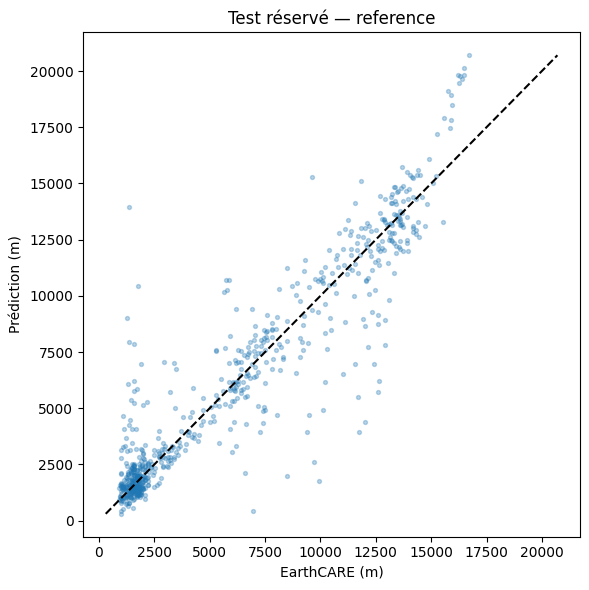

In [26]:
final_models, test_predictions, test_records = {}, {}, []
for name in dict.fromkeys(['reference', winner]):
    X, selection = experiments[name]
    model = make_model(X.shape[1], selection)
    model.fit(X.iloc[dev_idx], y.iloc[dev_idx]/1000)
    pred = model.predict(X.iloc[test_idx])*1000
    final_models[name] = model
    test_predictions[name] = pred
    test_records.append(dict(experience=name, population='test_complet', **metrics(y.iloc[test_idx], pred)))
    joblib.dump(model, OUT / f'modele_{name}.joblib')

test_table = data.iloc[test_idx][[DAY, TARGET] + ([TYPE] if TYPE in data else [])].copy()
for name, pred in test_predictions.items():
    test_table['prediction_' + name] = pred
if SAF in data:
    saf_pred = pd.to_numeric(data.iloc[test_idx][SAF], errors='coerce').to_numpy()
    test_table['prediction_SAFNWC'] = saf_pred
    common = np.isfinite(saf_pred)
    for pred in test_predictions.values():
        common &= np.isfinite(pred)
    for name, pred in {**test_predictions, 'SAFNWC': saf_pred}.items():
        test_records.append(dict(experience=name, population='test_commun_SAFNWC',
                                 **metrics(y.iloc[test_idx].to_numpy()[common], pred[common])))
final_scores = pd.DataFrame(test_records)
display(final_scores)
final_scores.to_csv(OUT / 'scores_test.csv', index=False)
test_table.to_csv(OUT / 'predictions_test.csv', index=False)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y.iloc[test_idx], test_predictions[winner], s=8, alpha=0.3)
limits = [min(y.iloc[test_idx].min(), test_predictions[winner].min()),
          max(y.iloc[test_idx].max(), test_predictions[winner].max())]
ax.plot(limits, limits, 'k--')
ax.set(xlabel='EarthCARE (m)', ylabel='Prédiction (m)', title=f'Test réservé — {winner}')
plt.tight_layout(); plt.savefig(OUT / 'predictions_test.png', dpi=150); plt.show()


## 9. Cas d'étude et traçabilité

Choisir une observation reproductible par type présent dans le test, puis montrer
son voisinage si disponible. Ces exemples illustrent les résultats sans remplacer
l'analyse de tous les points. La synthèse conserve aussi l'amplitude des erreurs par type.


,Day_UTC,Cloud_Top_Altitude_EarthCARE,Cloud_Type_SAFNWC,prediction_reference,prediction_SAFNWC,erreur_m
2302,20250628,1800.000000,5,2498.615701,1739.0,698.615701
2300,20250628,2350.000000,6,2336.545751,1745.0,-13.454249
2335,20250628,6300.000000,7,6062.799260,5650.0,-237.200740
2315,20250628,13300.000000,8,12336.560817,10326.0,-963.439183
2416,20250628,13633.333008,9,14780.066063,12921.0,1146.733055
2379,20250628,1450.000000,10,1036.541996,63535.0,-413.458004
2310,20250628,5200.000000,11,4416.065661,6200.0,-783.934339
2336,20250628,6200.000000,12,7025.095981,6356.0,825.095981
2366,20250628,11850.000000,13,15095.542238,12811.0,3245.542238
2349,20250628,11100.000000,14,12959.792057,11969.0,1859.792057


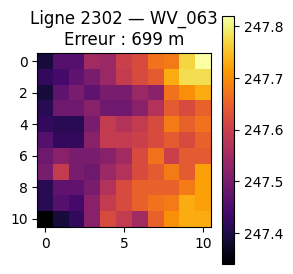

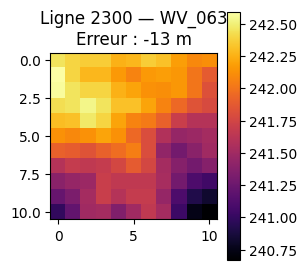

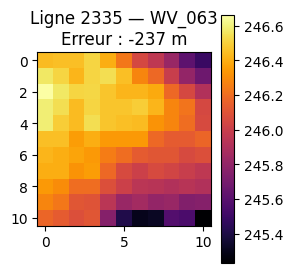

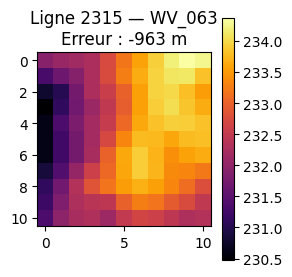

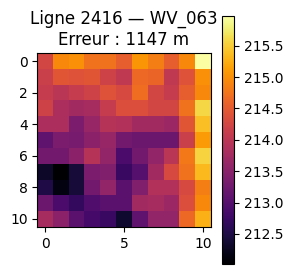

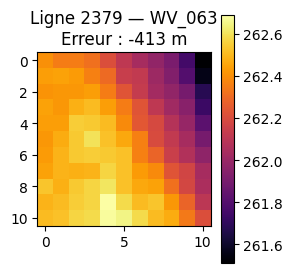

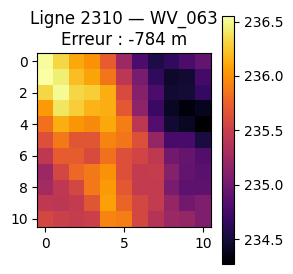

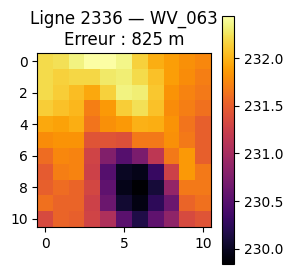

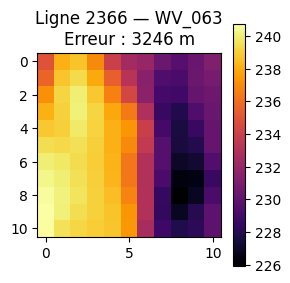

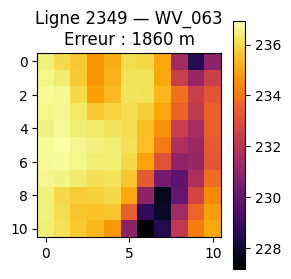

Résultats enregistrés dans : /kaggle/working/resultats_notebook


In [27]:
case_indices = []
if TYPE in test_table:
    for ct, part in test_table.groupby(TYPE):
        case_indices.append(part.index[0])
else:
    case_indices = list(test_table.index[:4])
cases = test_table.loc[case_indices].copy()
cases['erreur_m'] = cases['prediction_' + winner] - cases[TARGET]
display(cases)
cases.to_csv(OUT / 'cas_etude.csv', index=True)
for i in case_indices:
    available = [(c, as_patch(data.at[i, c])) for c in patch_channels]
    available = [(c, p) for c, p in available if p is not None]
    if available:
        channel, patch = available[0]
        fig, ax = plt.subplots(figsize=(3, 3))
        im = ax.imshow(patch, cmap='inferno')
        ax.set_title(f'Ligne {i} — {channel}\nErreur : {cases.at[i, "erreur_m"]:.0f} m')
        fig.colorbar(im, ax=ax); plt.tight_layout()
        plt.savefig(OUT / f'cas_{i}.png', dpi=150); plt.show()

versions = {package: importlib.metadata.version(package) for package in
            ['numpy','pandas','pyarrow','scikit-learn','scikit-image','PyWavelets','matplotlib']}
manifest = dict(seed=SEED, python=platform.python_version(), versions=versions,
                target=TARGET, assumed_altitude_unit='m — à confirmer', rows=len(data), max_rows=MAX_ROWS,
                requested_folds=REQUESTED_FOLDS, used_folds=n_folds,
                test_dates=[str(d) for d in test_dates], winner=winner,
                max_iter=MAX_ITER, patch_layout_confirmed=PATCH_LAYOUT_CONFIRMED,
                patch_order=PATCH_ORDER, gabor_frequencies=GABOR_FREQUENCIES,
                gabor_angles=GABOR_ANGLES, wavelet=WAVELET,
                external_features=EXTERNAL_FEATURE_COLUMNS if USE_EXTERNAL_FEATURES else [],
                join_keys=JOIN_KEYS, positional_alignment=ALLOW_POSITIONAL_ALIGNMENT,
                feature_sets={name: list(X.columns) for name,(X,_) in experiments.items()},
                inputs={p.name: dict(bytes=p.stat().st_size, modified_ns=p.stat().st_mtime_ns)
                        for p in [PICKLE_PATH, SPATIAL_PATH]})
(OUT / 'configuration.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
print('Résultats enregistrés dans :', OUT)


## 10. Interpréter et préparer la suite

- Comparer les différences de MAE sur les mêmes folds (`scores_folds.csv`), leur stabilité
  et les effectifs de chaque type de nuage. Ne pas conclure sur la seule meilleure moyenne.
- Vérifier la convergence, les unités, la chronologie et la provenance des caractéristiques.
- Si seuls les résultats de référence apparaissent, confirmer la disposition des vecteurs
  spatiaux puis relancer avec `PATCH_LAYOUT_CONFIRMED=True`, ou fournir des images 2D.
- Pour l'étude complète, utiliser `MAX_ROWS=None` après estimation du coût sur l'échantillon.
- Pour 50 folds, demander `REQUESTED_FOLDS=50` ; le notebook réduit explicitement ce nombre
  si le développement contient moins de 50 dates indépendantes.
- Une extension MTG/Himawari exige des images, leur géolocalisation, leur calibration
  et une colocalisation spatio-temporelle avec EarthCARE. Elle n'est pas simulée ici.

Les sorties du notebook sont exploratoires tant que les points de provenance et les
paramètres scientifiques ci-dessus n'ont pas été vérifiés avec le producteur des données.


In [28]:
import os
from IPython.display import FileLink, display

os.chdir("/kaggle/working")
display(FileLink("resultats_a_partager.zip"))


/kaggle/working/resultats_a_partager.zip